# PCA 1 — geometric blobs, projection, and reconstruction

**Goal:** rotate a 2D point cloud into principal coordinates, retain one component,
and measure what is lost. PCA produces numerical coordinates; it neither assigns
clusters nor learns class labels.

We will derive directions using a covariance matrix and an SVD, verify scikit-learn's
results, and show a case where almost all variance is retained while class information
disappears. No downloads, external CSV files, or GPU are needed. Run cells in order;
figures are also exported to `figures/` for the PDF.

## 1. Imports
`PCA.fit` learns the mean and directions. `transform` projects rows; `inverse_transform` reconstructs them. We use the full SVD and leave whitening disabled.

In [1]:
from pathlib import Path
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.decomposition import PCA

SEED = 23
COLORS = ["#147d92", "#e49b32", "#8b62a9"]
plt.rcParams.update({"figure.dpi": 115, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlesize": 12})
ROOT = Path.cwd()
if (ROOT / "PCA").is_dir():
    ROOT = ROOT / "PCA"
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)
(ROOT / ".build").mkdir(exist_ok=True)

def save_figure(fig, name):
    fig.savefig(FIGURES / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIGURES / f"{name}.png", dpi=160, bbox_inches="tight")

print(f"Python {platform.python_version()} | scikit-learn {sklearn.__version__}")

Python 3.12.9 | scikit-learn 1.8.0


## 2. Generate a rotated cloud with three blobs

Draw 200 points around each of three centers along a latent horizontal axis,
then rotate by 32 degrees and translate. Both observed coordinates share units.
`blob_for_audit` is used only to color a later plot; PCA sees only `X`.
Centering removes the translation, while rotation preserves Euclidean distances.

In [2]:
rng = np.random.default_rng(SEED)
blob_for_audit = np.repeat(np.arange(3), 200)
latent = rng.normal(size=(600, 2)) * np.array([0.65, 0.35])
latent[:, 0] += np.repeat([-3.0, 0.0, 3.0], 200)
angle = np.deg2rad(32)
rotation = np.array([[np.cos(angle), -np.sin(angle)],
                     [np.sin(angle), np.cos(angle)]])
X = latent @ rotation.T + np.array([2.0, -1.0])
assert X.shape == (600, 2) and np.isfinite(X).all()
pca_full = PCA(n_components=2, svd_solver="full", whiten=False).fit(X)
scores = pca_full.transform(X)
display(pd.DataFrame(pca_full.components_, columns=["x coefficient", "y coefficient"],
                     index=["PC1 direction", "PC2 direction"]).round(4))
display(pd.DataFrame({"variance": pca_full.explained_variance_,
                      "variance_fraction": pca_full.explained_variance_ratio_},
                     index=["PC1", "PC2"]).round(4))

,x coefficient,y coefficient
PC1 direction,0.8493,0.5279
PC2 direction,-0.5279,0.8493


,variance,variance_fraction
PC1,6.3160,0.9812
PC2,0.1207,0.0188


## 3. Inspect directions and scores

`components_` stores one unit direction per row. A score is one observation's
coordinate along that direction: $T=(X-\bar X)V$, where the columns of $V$
are directions. Arrows below extend two component standard deviations from
the mean. Their lengths visualize spread; the direction vectors themselves are unit length.

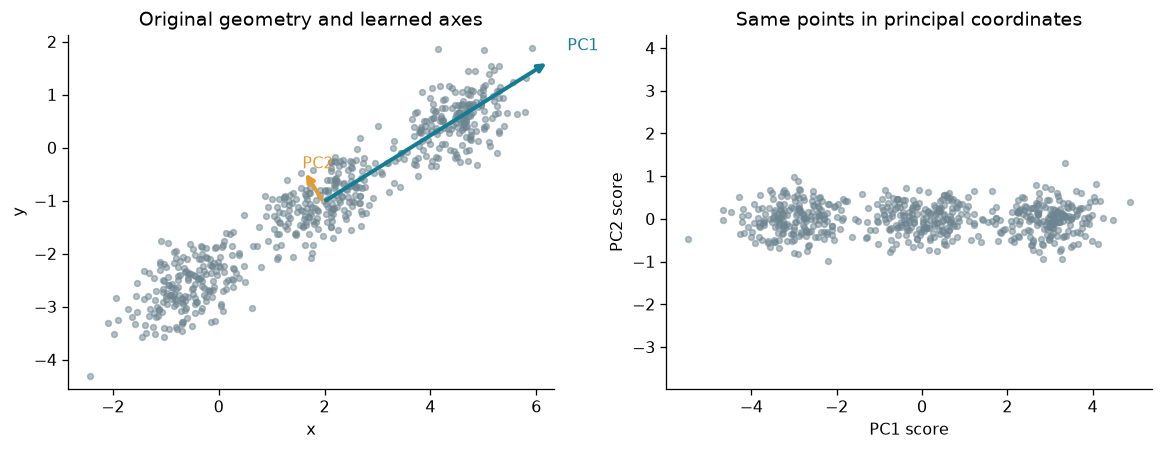

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), constrained_layout=True)
axes[0].scatter(*X.T, s=13, color="#6d8590", alpha=0.5)
for j, color in enumerate(COLORS[:2]):
    delta = 2 * np.sqrt(pca_full.explained_variance_[j]) * pca_full.components_[j]
    axes[0].annotate("", xy=pca_full.mean_+delta, xytext=pca_full.mean_,
                     arrowprops={"arrowstyle": "->", "color": color, "lw": 2.5})
    axes[0].text(*(pca_full.mean_+1.08*delta), f"PC{j+1}", color=color)
axes[0].set(title="Original geometry and learned axes", xlabel="x", ylabel="y")
axes[1].scatter(*scores.T, s=13, color="#6d8590", alpha=0.5)
axes[1].set(title="Same points in principal coordinates", xlabel="PC1 score", ylabel="PC2 score")
for ax in axes:
    ax.set_aspect("equal", adjustable="datalim")
save_figure(fig, "geometry_axes")
plt.show()

## 4. Audit covariance eigenvectors and the SVD

The sample covariance is $S=X_c^T X_c/(n-1)$, with $X_c=X-\bar X$.
`eigh` returns eigenvalues in ascending order, so reverse their order.
If $X_c=UDV^T$, then $\lambda_j=d_j^2/(n-1)$.
Compare projection matrices rather than signs: $v$ and $-v$ define the same line.
Fitting scores have diagonal sample covariance, but need not be statistically independent.

In [4]:
centered = X - X.mean(axis=0)
covariance = centered.T @ centered / (len(X) - 1)
eigenvalues, eigenvectors = np.linalg.eigh(covariance)
order = np.argsort(eigenvalues)[::-1]
eigenvalues, eigenvectors = eigenvalues[order], eigenvectors[:, order]
U, singular_values, Vt = np.linalg.svd(centered, full_matrices=False)
np.testing.assert_allclose(eigenvalues, pca_full.explained_variance_)
np.testing.assert_allclose(singular_values**2/(len(X)-1), eigenvalues)
np.testing.assert_allclose(scores, centered @ pca_full.components_.T)
np.testing.assert_allclose(pca_full.components_ @ pca_full.components_.T, np.eye(2), atol=1e-12)
np.testing.assert_allclose(np.outer(eigenvectors[:, 0], eigenvectors[:, 0]),
                           np.outer(pca_full.components_[0], pca_full.components_[0]))
np.testing.assert_allclose(np.cov(scores, rowvar=False), np.diag(eigenvalues), atol=1e-12)
print("Covariance eigenvalues:", eigenvalues.round(5))
print("All covariance/SVD/projection checks passed")

Covariance eigenvalues: [6.316   0.12072]
All covariance/SVD/projection checks passed


## 5. Reduce 2D to 1D, then reconstruct

Keep one score per row: $t_i=(x_i-\bar x)^T v_1$.
Reconstruct $\hat x_i=\bar x+t_i v_1$; the missing coordinate is replaced
by its mean in principal coordinates. The discarded perpendicular residual is
orthogonal to the retained direction. Report squared error per original scalar entry.

The fitting-set identity is
$\|X-\hat X\|_F^2=(n-1)\sum_{j>q}\lambda_j$.
It connects explained variance to reconstruction error on the data used to fit PCA.

,PC1 score,original x,reconstructed x
0,-2.608,-0.280,-0.238
1,-3.003,-0.146,-0.573
2,-2.685,0.088,-0.303
3,-2.376,-0.155,-0.041
4,-2.429,-0.240,-0.085
5,-2.773,-0.280,-0.378


Retained variance: 98.12%; reconstruction MSE per entry: 0.06026


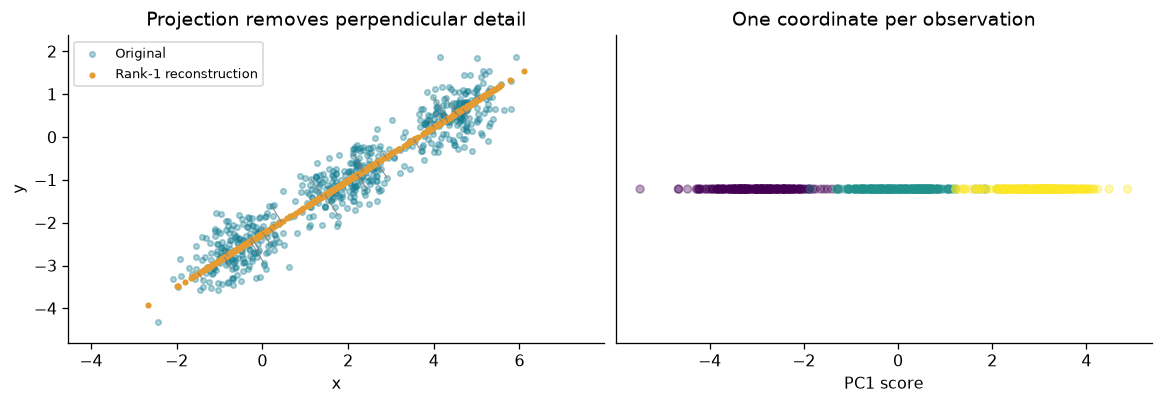

In [5]:
pca_one = PCA(n_components=1, svd_solver="full").fit(X)
one_score = pca_one.transform(X)
reconstructed = pca_one.inverse_transform(one_score)
residual = X - reconstructed
geometry_mse = float(np.mean(residual**2))
retained = float(pca_one.explained_variance_ratio_.sum())
np.testing.assert_allclose(np.sum(residual**2), (len(X)-1)*eigenvalues[1], rtol=1e-10)
np.testing.assert_allclose(residual @ pca_one.components_.T, 0, atol=1e-12)
np.testing.assert_allclose(pca_full.inverse_transform(scores), X, atol=1e-12)
display(pd.DataFrame({"PC1 score": one_score[:6, 0], "original x": X[:6, 0],
                      "reconstructed x": reconstructed[:6, 0]}).round(3))
print(f"Retained variance: {retained:.2%}; reconstruction MSE per entry: {geometry_mse:.5f}")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), constrained_layout=True)
axes[0].scatter(*X.T, s=12, color=COLORS[0], alpha=0.35, label="Original")
axes[0].scatter(*reconstructed.T, s=8, color=COLORS[1], label="Rank-1 reconstruction")
for index in range(0, len(X), 20):
    axes[0].plot([X[index, 0], reconstructed[index, 0]],
                 [X[index, 1], reconstructed[index, 1]], color="0.5", lw=0.6)
axes[0].set(title="Projection removes perpendicular detail", xlabel="x", ylabel="y")
axes[0].set_aspect("equal", adjustable="datalim")
axes[0].legend(fontsize=8)
axes[1].scatter(one_score[:, 0], np.zeros(len(X)), c=blob_for_audit,
                cmap="viridis", s=24, alpha=0.35)
axes[1].set(title="One coordinate per observation", xlabel="PC1 score", yticks=[])
save_figure(fig, "geometry_reconstruction")
plt.show()

## 6. Almost all variance can still lose all class information

Build two parallel horizontal bands with exactly the same x positions and
y=−0.25 or +0.25. Band membership is the class. PC1 keeps the large horizontal
variation and discards the small vertical separation. Paired points from opposite
classes have identical PC1 scores, so these scores cannot distinguish their labels.
Class labels only color this diagnostic; PCA is still fitted without them.

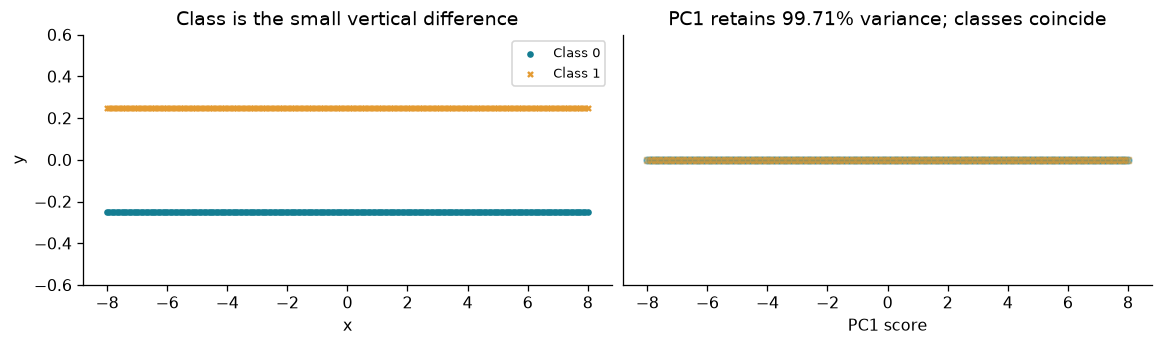

Variance retained: 99.7108%; paired opposite-class scores are identical


178

In [6]:
horizontal = np.linspace(-8, 8, 200)
bands = np.column_stack([np.tile(horizontal, 2), np.repeat([-0.25, 0.25], 200)])
band_class = np.repeat([0, 1], 200)
band_pca = PCA(n_components=1, svd_solver="full").fit(bands)
band_scores = band_pca.transform(bands)
np.testing.assert_allclose(band_scores[:200], band_scores[200:], atol=1e-12)
band_retained = float(band_pca.explained_variance_ratio_[0])
fig, axes = plt.subplots(1, 2, figsize=(10, 2.9), constrained_layout=True)
for group, color, marker in zip([0, 1], COLORS, ["o", "x"]):
    mask = band_class == group
    axes[0].scatter(*bands[mask].T, color=color, s=10, marker=marker, label=f"Class {group}")
    axes[1].scatter(band_scores[mask, 0], np.zeros(mask.sum()),
                    color=color, s=17, marker=marker, alpha=0.5)
axes[0].set(title="Class is the small vertical difference", xlabel="x", ylabel="y", ylim=(-0.6, 0.6))
axes[0].legend(fontsize=8)
axes[1].set(title=f"PC1 retains {band_retained:.2%} variance; classes coincide", xlabel="PC1 score", yticks=[])
save_figure(fig, "variance_vs_class")
plt.show()
print(f"Variance retained: {band_retained:.4%}; paired opposite-class scores are identical")
summary = {"retained": retained, "mse": geometry_mse,
           "eigenvalues": eigenvalues.tolist(), "band_retained": band_retained}
(ROOT / ".build" / "geometry_metrics.json").write_text(json.dumps(summary, indent=2) + "\n")

## 7. Exercises with reference solutions

1. Flip the sign of the retained direction and its scores. Verify that reconstruction
   stays unchanged. Explain why a direction's sign is not scientifically meaningful.
2. Multiply observed coordinate y by 100. Compare the one-component explained-variance
   fraction before and after standardization. Does one fraction establish better science?
   Interpret both using their different distance geometries.

In [7]:
# Reference solution 1
flipped_reconstruction = pca_one.mean_ + (-one_score) @ (-pca_one.components_)
np.testing.assert_allclose(flipped_reconstruction, reconstructed)
print("Direction and score sign flips cancel in reconstruction")

# Reference solution 2
from sklearn.preprocessing import StandardScaler
changed_units = X * np.array([1.0, 100.0])
raw_units = PCA(n_components=1, svd_solver="full").fit(changed_units)
standardizer = StandardScaler().fit(changed_units)
equal_variance = PCA(n_components=1, svd_solver="full").fit(standardizer.transform(changed_units))
display(pd.DataFrame({"geometry": ["changed units", "standardized"],
    "PC1 variance fraction": [raw_units.explained_variance_ratio_[0],
                              equal_variance.explained_variance_ratio_[0]]}).round(5))
# These fractions describe different total-variance denominators.

Direction and score sign flips cancel in reconstruction


,geometry,PC1 variance fraction
0,changed units,0.99998
1,standardized,0.97699


## Sources and attribution

Companion reading: GeeksforGeeks, [Principal Component Analysis (PCA)](https://www.geeksforgeeks.org/data-analysis/principal-component-analysis-pca/)
(accessed 27 October 2026). The PDF includes a short attributed paraphrase and two credited
figures from that article. This notebook's code, experiments, and plots are original to this supplement.

Technical references: scikit-learn [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html),
[decomposition guide](https://scikit-learn.org/stable/modules/decomposition.html#pca), and
[preventing data leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).
Full credits: [ATTRIBUTION.md](ATTRIBUTION.md).